# 02: PatchCore ve PaDiM ile anomali tespiti (MVTec AD)

anomalib 2.7.0 ile 4 kategoride (metal_nut, leather, screw, transistor) denetimsiz anomali tespiti.
Modeller yalnızca sağlam görüntülerle "eğitildi". Image AUROC, skorlardan `roc_auc_score` ile elle hesaplandı.

Veri seti: MVTec AD (CC BY-NC-SA 4.0). Bergmann et al., CVPR 2019.

In [1]:
import torch
print(torch.cuda.is_available())

True


## 1. Kurulum
GPU kontrolü ve anomalib 2.7.0 kurulumu.

In [2]:
!pip install anomalib

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 72.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.9/803.9 kB 33.6 MB/s eta 0:00:00
  Created wheel for freia: filename=freia-0.2-py3-none-any.whl size=42848 sha256=ab8d1f0ae3dad9e5230141cc54d237aa92c79896d8ec41cf80f0d25161cc3426
  Stored in directory: /root/.cache/pip/wheels/b1/66/ba/29fd62b92bba7c42af99ae475baafa7d205b2c3e7fcc8670b7
Successfully built freia


In [3]:
import anomalib, os
print(anomalib.__version__)
print(os.listdir("/kaggle/input/datasets/ipythonx/mvtec-ad")[:5])

2.7.0
['bottle', 'cable', 'capsule', 'carpet', 'grid']


## 2. PatchCore betiği
Notebook içinde çalıştırınca ilerleme çubuğu (tqdm/rich) RecursionError verdiği için kod bir betiğe yazılıp ayrı süreç olarak çalıştırıldı.

In [4]:
%%writefile patchcore_calistir.py
import sys, json, os
import torch
from sklearn.metrics import roc_auc_score
from anomalib.data import MVTecAD
from anomalib.models import Patchcore
from anomalib.engine import Engine

ROOT = "/kaggle/input/datasets/ipythonx/mvtec-ad"
DOSYA = "/kaggle/working/sonuclar.json"

def calistir(kategori):
    datamodule = MVTecAD(
        root=ROOT, category=kategori,
        train_batch_size=16, eval_batch_size=16, num_workers=2,
    )
    model = Patchcore()
    engine = Engine(default_root_dir=f"/kaggle/working/results/{kategori}")
    engine.fit(datamodule=datamodule, model=model)
    tahminler = engine.predict(model=model, dataloaders=datamodule.test_dataloader())
    skor   = torch.cat([p.pred_score.flatten().cpu() for p in tahminler]).numpy()
    etiket = torch.cat([p.gt_label.flatten().cpu() for p in tahminler]).numpy()
    return float(roc_auc_score(etiket, skor))

for k in sys.argv[1:]:
    a = calistir(k)
    print("SONUC", k, "image AUROC:", round(a, 4), flush=True)
    sonuc = json.load(open(DOSYA)) if os.path.exists(DOSYA) else {}
    sonuc[k] = a
    json.dump(sonuc, open(DOSYA, "w"))

Writing patchcore_calistir.py


## 3. PatchCore sonuçları
| Kategori | Image AUROC |
|---|---|
| metal_nut | 0.997 |
| leather | 1.000 |
| screw | 0.961 |
| transistor | 0.993 |
| **Ortalama** | **0.988** |

In [5]:
!python patchcore_calistir.py metal_nut 2>&1 | grep -E "SONUC|Error|error|Traceback"

SONUC metal_nut image AUROC: 0.999


In [6]:
   !python patchcore_calistir.py leather 2>&1 | tail -30

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer
┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type           ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │ 24.9 M │ train │     0 │
└───┴─────────────

In [7]:
!python patchcore_calistir.py screw 2>&1 | tail -5

ckpt_path is not provided. Model weights will not be loaded.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 0:00:19 • 0:00:00 0.48it/s 
SONUC screw image AUROC: 0.9717


In [8]:
!python patchcore_calistir.py transistor 2>&1 | tail -5

ckpt_path is not provided. Model weights will not be loaded.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 0:00:16 • 0:00:00 0.36it/s 
SONUC transistor image AUROC: 0.9917


## 4. PaDiM karşılaştırması
| Kategori | Image AUROC |
|---|---|
| metal_nut | 0.998 |
| leather | 1.000 |
| screw | 0.956 |
| transistor | 0.994 |
| **Ortalama** | **0.987** |

İki model arasındaki fark binde birler düzeyinde, anlamlı sayılmaz. En zor kategori: screw.

In [9]:
import json
print(json.load(open("/kaggle/working/sonuclar.json")))

{'metal_nut': 0.9990224828934506, 'leather': 1.0, 'screw': 0.9717155154744825, 'transistor': 0.9916666666666667}


## 5. Isı haritaları (metal_nut)
PatchCore anomali haritaları gerçek maskelerle örtüşüyor. İncelenen 6 örnek aynı kusur türünden, genelleme yapılmamalı.

In [10]:
%%writefile isi_haritasi.py
import sys
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from anomalib.data import MVTecAD
from anomalib.models import Patchcore
from anomalib.engine import Engine

ROOT = "/kaggle/input/datasets/ipythonx/mvtec-ad"
kategori = sys.argv[1]

datamodule = MVTecAD(root=ROOT, category=kategori,
                     train_batch_size=16, eval_batch_size=16, num_workers=2)
model = Patchcore()
engine = Engine(default_root_dir=f"/kaggle/working/results/{kategori}")
engine.fit(datamodule=datamodule, model=model)
tahminler = engine.predict(model=model, dataloaders=datamodule.test_dataloader())

import os
os.makedirs("/kaggle/working/haritalar", exist_ok=True)

kaydedilen = 0
for batch in tahminler:
    for i in range(len(batch.pred_score)):
        if int(batch.gt_label[i]) == 0:
            continue                      # sadece kusurlu görüntüler
        if kaydedilen >= 6:
            break
        img  = batch.image[i].cpu().permute(1, 2, 0).numpy()
        img  = (img - img.min()) / (img.max() - img.min() + 1e-8)
        harita = batch.anomaly_map[i].squeeze().cpu().numpy()
        maske  = batch.gt_mask[i].squeeze().cpu().numpy()

        fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
        ax[0].imshow(img);            ax[0].set_title("Görüntü")
        ax[1].imshow(maske, cmap="gray"); ax[1].set_title("Gerçek maske")
        ax[2].imshow(img); ax[2].imshow(harita, cmap="jet", alpha=0.5)
        ax[2].set_title(f"Isı haritası (skor {float(batch.pred_score[i]):.1f})")
        for a in ax: a.axis("off")
        plt.savefig(f"/kaggle/working/haritalar/{kategori}_{kaydedilen}.png",
                    bbox_inches="tight")
        plt.close()
        kaydedilen += 1
print("TAMAM", kaydedilen, "harita kaydedildi")

Writing isi_haritasi.py


In [11]:
!python isi_haritasi.py metal_nut 2>&1 | tail -15

Total params: 24.9 M                                                            
Total estimated model params size (MB): 99.450                                  
Modules in train mode: 19                                                       
Modules in eval mode: 174                                                       
Total FLOPs: 0                                                                  
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 174 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 22527/22527 [01:17<00:00, 292.28it/s]
`Trainer.fit` stopped: `max_epochs=1` reached.
Epoch 0/0  ━━━━━━━

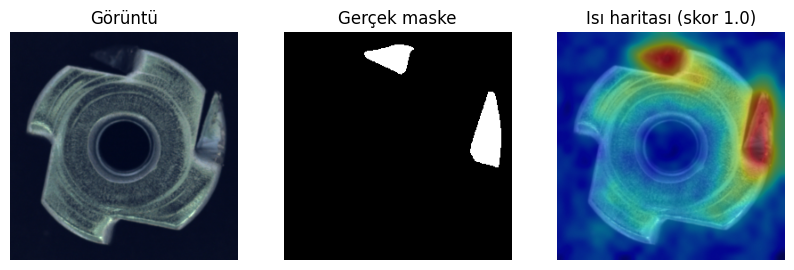

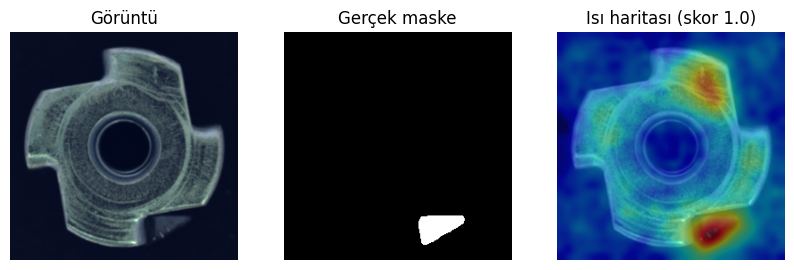

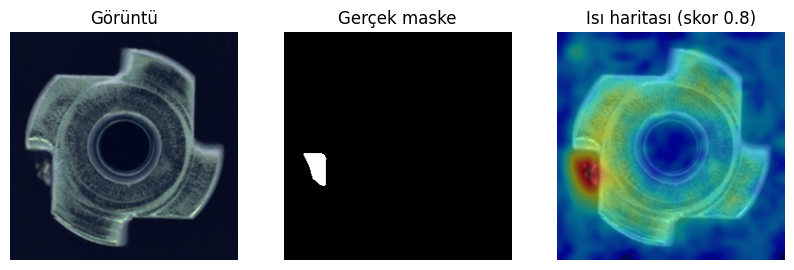

In [12]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("/kaggle/working/haritalar/metal_nut_*.png"))[:3]:
    display(Image(f))

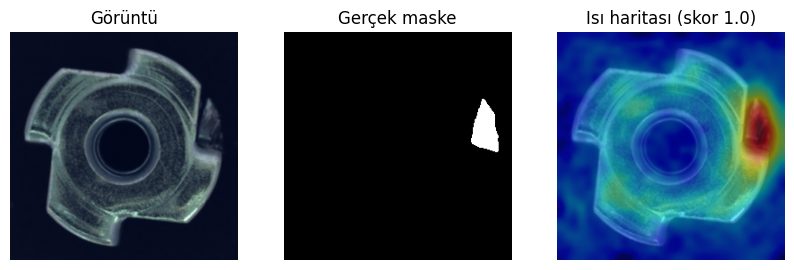

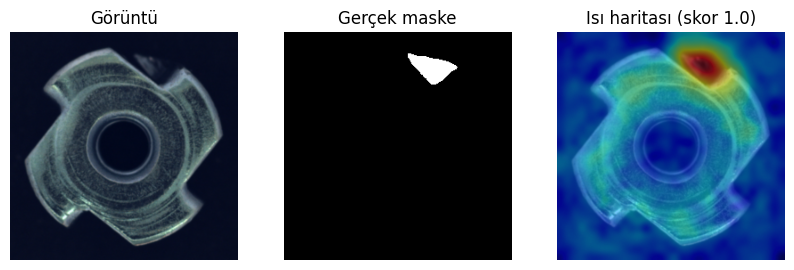

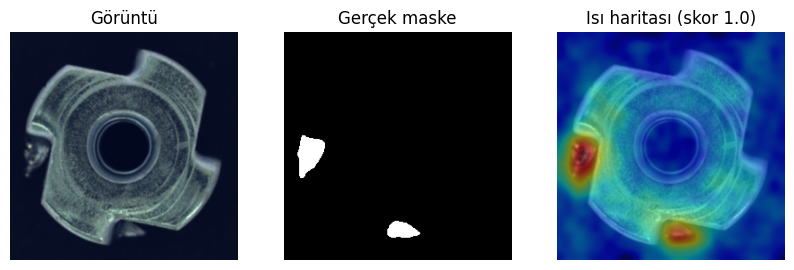

In [13]:
for f in sorted(glob.glob("/kaggle/working/haritalar/metal_nut_*.png"))[3:6]:
    display(Image(f))